# Sign Language Recognition using Temporal Classification
## Part 1: Data and Preprocessing (Person 1)

**Goal:** turn WLASL videos for ~25 signs into fixed-size landmark sequences `X` of shape `(num_samples, T, 144)` with integer labels `y`, split into train / val / test, ready for the model.

**Pipeline:** select 25 signs → analyse dataset → extract MediaPipe landmarks → quality filter → spatial normalisation → fill missing → temporal resampling → build arrays → split → augment (train only) → save.

> Kaggle setup: attach the WLASL dataset, and turn **Internet ON** in the notebook settings (needed for `pip install`).

## 1. Setup
Install MediaPipe, import libraries and set the config. Change values here, not later in the notebook.

In [1]:
%pip uninstall -y tensorflow
%pip install mediapipe==0.10.14

Found existing installation: tensorflow 2.20.0
Uninstalling tensorflow-2.20.0:
  Successfully uninstalled tensorflow-2.20.0
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 56.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 15.4 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
a2a-sdk 0

In [2]:
!rm -rf /usr/local/lib/python3.12/dist-packages/tensorflow* /usr/local/lib/python3.12/dist-packages/~ensorflow*

In [3]:
import mediapipe as mp
print(mp.__version__, mp.solutions.holistic)

0.10.14 <module 'mediapipe.python.solutions.holistic' from '/usr/local/lib/python3.12/dist-packages/mediapipe/python/solutions/holistic.py'>


In [4]:
import os, glob, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- CONFIG ----------------
NUM_CLASSES = 25            # how many signs (words) to use
T = 40                      # fixed number of time steps per sequence
MAX_FRAMES_TO_PROCESS = 64  # sample at most this many frames per video (speeds up extraction)
SPLIT_MODE = "official"     # "official" (split given in WLASL json) or "random" (stratified 70/15/15)
USE_FRAME_BOUNDS = False    # True = trim videos using frame_start/frame_end from the json
MIN_POSE_RATE = 0.70        # keep a video only if upper body detected in >= 70% of frames
MIN_HAND_RATE = 0.40        # ... and at least one hand detected in >= 40% of frames

WORK_DIR = "/kaggle/working"
RAW_DIR = f"{WORK_DIR}/landmarks_raw"   # per-video raw landmarks (cache, lets you resume)
OUT_DIR = f"{WORK_DIR}/processed"       # final arrays
FIG_DIR = f"{OUT_DIR}/figures"          # plots for the report
for d in (RAW_DIR, OUT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

## 2. Locate the dataset files
Finds `WLASL_v0.3.json` and builds a lookup from `video_id` to the video file path.

In [5]:
json_hits = glob.glob("/kaggle/input/**/WLASL_v0.3.json", recursive=True)
assert json_hits, "WLASL_v0.3.json not found. Is the dataset attached to this notebook?"
json_path = json_hits[0]

video_paths = {}
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
            video_paths[os.path.splitext(f)[0]] = os.path.join(root, f)

print("JSON:", json_path)
print("Video files found:", len(video_paths))

JSON: /kaggle/input/datasets/risangbaskoro/wlasl-processed/WLASL_v0.3.json
Video files found: 11980


## 3. Load annotations
Flatten the JSON (one entry per sign, each with many video instances) into a table with one row per video.

In [6]:
with open(json_path) as f:
    wlasl = json.load(f)

rows = []
for entry in wlasl:
    for inst in entry["instances"]:
        rows.append(dict(
            gloss=entry["gloss"],
            video_id=str(inst["video_id"]),
            signer_id=inst.get("signer_id"),
            split=inst.get("split"),
            frame_start=inst.get("frame_start", 1),
            frame_end=inst.get("frame_end", -1),
        ))
df = pd.DataFrame(rows)
df["exists"] = df.video_id.isin(video_paths)

print("Total glosses:", df.gloss.nunique(), "| total instances:", len(df))
print("Instances with a video file on disk:", int(df.exists.sum()))
df.head()

Total glosses: 2000 | total instances: 21083
Instances with a video file on disk: 11980


,gloss,video_id,signer_id,split,frame_start,frame_end,exists
0,book,69241,118,train,1,-1,True
1,book,65225,90,train,1,-1,False
2,book,68011,110,train,1,-1,False
3,book,68208,113,train,1,60,False
4,book,68012,109,train,1,-1,False


## 4. Select 25 signs
Many WLASL videos are missing, so we only count videos that actually exist, then take the 25 signs with the most videos (more samples per class = better model).

In [7]:
avail = df[df.exists]
counts = avail.groupby("gloss").size().sort_values(ascending=False)
selected = counts.head(NUM_CLASSES).index.tolist()

sub = avail[avail.gloss.isin(selected)].reset_index(drop=True)
print("Selected signs:", selected)
print("Videos per sign: min", counts[selected].min(), "| max", counts[selected].max(), "| total", len(sub))

Selected signs: ['thin', 'cool', 'before', 'go', 'drink', 'help', 'who', 'computer', 'cousin', 'accident', 'thanksgiving', 'trade', 'bed', 'candy', 'tall', 'bowling', 'short', 'last', 'call', 'later', 'what', 'basketball', 'change', 'man', 'corn']
Videos per sign: min 12 | max 16 | total 334


## 5. Dataset analysis
Class balance, split sizes, signers and video properties. These plots go straight into the write-up.

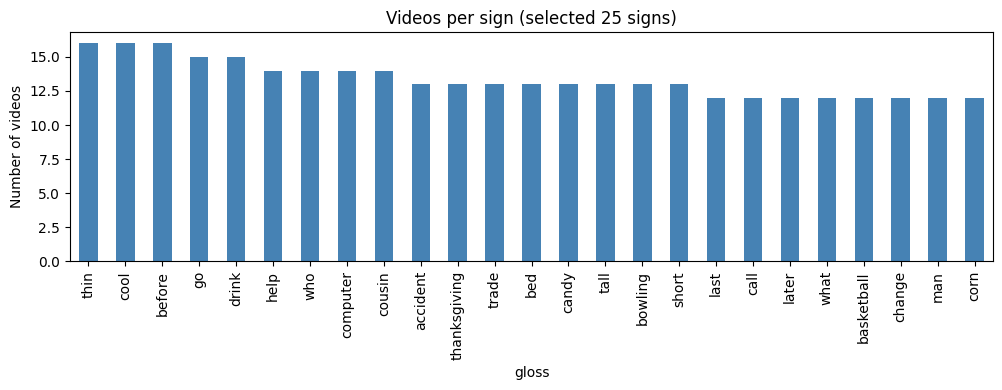

Samples per split:
split         test  train  val
gloss                         
accident         2      9    2
basketball       1      9    2
bed              0     12    1
before           3     12    1
bowling          1     10    2
call             2      8    2
candy            3      8    2
change           1      9    2
computer         1     10    3
cool             2     11    3
corn             2     10    0
cousin           2      9    3
drink            1     11    3
go               1     11    3
help             2     10    2
last             2      8    2
later            0      8    4
man              0     10    2
short            1      9    3
tall             1     10    2
thanksgiving     1      9    3
thin             2     11    3
trade            1     10    2
what             3      6    3
who              1     10    3

Unique signers in selected data: 53


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
counts[selected].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Videos per sign (selected 25 signs)"); ax.set_ylabel("Number of videos")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/class_distribution.png", dpi=150); plt.show()

print("Samples per split:")
print(pd.crosstab(sub.gloss, sub.split))
print("\nUnique signers in selected data:", sub.signer_id.nunique())

  0%|          | 0/334 [00:00<?, ?it/s]

       n_frames    fps   width  height
count     334.0  334.0   334.0   334.0
mean       64.1   28.3   872.9   517.7
std        27.2    2.7   615.4   331.7
min        20.0   24.0   288.0   180.0
25%        43.0   25.0   320.0   240.0
50%        60.5   30.0   656.0   400.0
75%        85.5   30.0  1280.0   720.0
max       195.0   30.4  1920.0  1080.0


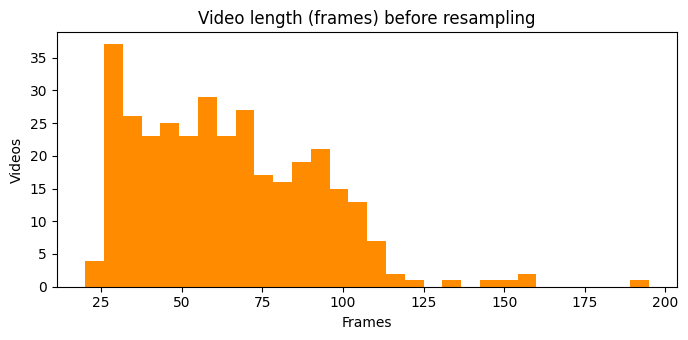

In [9]:
# Video properties (reads headers only, fast)
n_frames, fps, widths, heights = [], [], [], []
for vid in tqdm(sub.video_id):
    cap = cv2.VideoCapture(video_paths[vid])
    n_frames.append(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    fps.append(cap.get(cv2.CAP_PROP_FPS))
    widths.append(int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
    heights.append(int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release()
sub["n_frames"], sub["fps"], sub["width"], sub["height"] = n_frames, fps, widths, heights

print(sub[["n_frames", "fps", "width", "height"]].describe().round(1))
plt.figure(figsize=(7, 3.5))
plt.hist(sub.n_frames, bins=30, color="darkorange")
plt.title("Video length (frames) before resampling"); plt.xlabel("Frames"); plt.ylabel("Videos")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/video_lengths.png", dpi=150); plt.show()

## 6. Landmark extraction (MediaPipe Holistic)
Per frame we keep **144 features**: 6 upper-body pose points (shoulders, elbows, wrists) + 21 left-hand + 21 right-hand points, each with x, y, z.
Undetected parts are stored as `NaN` and handled later. Each video is cached to disk, so if the session stops you can re-run and it resumes.

Feature layout: `[0:18]` pose, `[18:81]` left hand, `[81:144]` right hand.

In [10]:
mp_holistic = mp.solutions.holistic
POSE_IDS = [11, 12, 13, 14, 15, 16]   # L/R shoulder, L/R elbow, L/R wrist
N_FEATS = (len(POSE_IDS) + 21 + 21) * 3   # 144
POSE_SL, LH_SL, RH_SL = slice(0, 18), slice(18, 81), slice(81, 144)

def landmarks_to_vector(res):
    v = np.full(N_FEATS, np.nan, dtype=np.float32)
    if res.pose_landmarks:
        lm = res.pose_landmarks.landmark
        v[POSE_SL] = np.array([[lm[i].x, lm[i].y, lm[i].z] for i in POSE_IDS]).ravel()
    if res.left_hand_landmarks:
        v[LH_SL] = np.array([[p.x, p.y, p.z] for p in res.left_hand_landmarks.landmark]).ravel()
    if res.right_hand_landmarks:
        v[RH_SL] = np.array([[p.x, p.y, p.z] for p in res.right_hand_landmarks.landmark]).ravel()
    return v

def extract_video_landmarks(path, start=1, end=-1):
    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        frames.append(fr)
    cap.release()
    if USE_FRAME_BOUNDS:
        frames = frames[max(int(start) - 1, 0): (int(end) if end and end > 0 else None)]
    if len(frames) == 0:
        return None
    keep = np.linspace(0, len(frames) - 1, min(len(frames), MAX_FRAMES_TO_PROCESS)).astype(int)
    out = np.full((len(keep), N_FEATS), np.nan, dtype=np.float32)
    with mp_holistic.Holistic(static_image_mode=False, model_complexity=1,
                              min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
        for i, k in enumerate(keep):
            rgb = cv2.cvtColor(frames[k], cv2.COLOR_BGR2RGB)
            out[i] = landmarks_to_vector(holistic.process(rgb))
    return out

In [11]:
# Quick test on 2 videos first (should print shape like (N, 144))
test = sub.iloc[0]
arr = extract_video_landmarks(video_paths[test.video_id], test.frame_start, test.frame_end)
print(test.gloss, arr.shape, "| NaN fraction:", round(float(np.isnan(arr).mean()), 3))

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791040708.760749    1481 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040708.780597    1481 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040708.781506    1481 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040708.782636    1481 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040708.781508    1479 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040708.789940    1

drink (64, 144) | NaN fraction: 0.567


In [12]:
# Full extraction (can take 20-40 min for ~600 videos; safe to re-run, finished videos are skipped)
failed = []
for r in tqdm(sub.itertuples(), total=len(sub)):
    out_file = f"{RAW_DIR}/{r.video_id}.npy"
    if os.path.exists(out_file):
        continue
    try:
        arr = extract_video_landmarks(video_paths[r.video_id], r.frame_start, r.frame_end)
        if arr is None:
            failed.append(r.video_id); continue
        np.save(out_file, arr)
    except Exception as e:
        failed.append(r.video_id)
print("Extracted:", len(os.listdir(RAW_DIR)), "| failed:", len(failed))

  0%|          | 0/334 [00:00<?, ?it/s]

W0000 00:00:1791040713.270669    1493 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040713.288084    1493 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040713.289101    1495 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040713.289174    1496 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040713.289532    1493 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791040713.294799    1493 inference_feedback_manager.cc:114] Feedback manager 

Extracted: 334 | failed: 0


## 7. Quality filter
Drop videos where the body or hands were rarely detected (bad crops, tiny signers, corrupted files). Detection rates also make a good table for the report.

In [13]:
def detection_rates(raw):
    pose = ~np.isnan(raw[:, POSE_SL]).any(1)
    lh = ~np.isnan(raw[:, LH_SL]).any(1)
    rh = ~np.isnan(raw[:, RH_SL]).any(1)
    return pose.mean(), (lh | rh).mean()

q = []
for r in sub.itertuples():
    f = f"{RAW_DIR}/{r.video_id}.npy"
    if os.path.exists(f):
        p, h = detection_rates(np.load(f))
        q.append((r.video_id, p, h))
quality = pd.DataFrame(q, columns=["video_id", "pose_rate", "hand_rate"])
sub_q = sub.merge(quality, on="video_id")
sub_q["keep"] = (sub_q.pose_rate >= MIN_POSE_RATE) & (sub_q.hand_rate >= MIN_HAND_RATE)

print(f"Kept {int(sub_q.keep.sum())} of {len(sub_q)} videos")
print(sub_q[["pose_rate", "hand_rate"]].describe().round(2))
sub_ok = sub_q[sub_q.keep].reset_index(drop=True)
print("\nVideos per sign after filtering (smallest 5):")
print(sub_ok.gloss.value_counts().tail(5))

Kept 298 of 334 videos
       pose_rate  hand_rate
count     334.00     334.00
mean        1.00       0.66
std         0.01       0.23
min         0.98       0.00
25%         1.00       0.48
50%         1.00       0.64
75%         1.00       0.81
max         1.00       1.00

Videos per sign after filtering (smallest 5):
gloss
who       10
short     10
cousin    10
what       9
candy      8
Name: count, dtype: int64


## 8. Preprocessing functions
1. **Spatial normalisation:** coordinates become relative to the mid-point between the shoulders and are divided by shoulder width, so camera distance and signer position don't matter.
2. **Fill missing:** undetected values are linearly interpolated over time (all-missing channels become 0).
3. **Temporal resampling:** every sequence is resampled to exactly `T` frames, so signing speed and video length are normalised.

`preprocess_video()` runs the whole chain on any video file, which we also reuse for the live demo.

In [14]:
def spatial_normalize(raw):
    a = raw.reshape(len(raw), -1, 3).astype(np.float64)   # (frames, 48 landmarks, xyz)
    ls, rs = a[:, 0, :], a[:, 1, :]                       # left / right shoulder
    valid = ~(np.isnan(ls).any(1) | np.isnan(rs).any(1))
    if valid.sum() == 0:
        return None
    center = np.median((ls[valid] + rs[valid]) / 2, axis=0)
    width = np.median(np.linalg.norm(ls[valid, :2] - rs[valid, :2], axis=1))
    if width < 1e-6:
        return None
    return ((a - center) / width).reshape(len(raw), -1)

def fill_missing(arr):
    out = arr.copy()
    idx = np.arange(len(arr))
    for j in range(out.shape[1]):
        col = out[:, j]
        ok = ~np.isnan(col)
        if ok.all():
            continue
        out[:, j] = 0.0 if not ok.any() else np.interp(idx, idx[ok], col[ok])
    return out

def resample_time(arr, t_new=T):
    n = len(arr)
    if n == 1:
        return np.repeat(arr, t_new, axis=0)
    old, new = np.linspace(0, 1, n), np.linspace(0, 1, t_new)
    return np.stack([np.interp(new, old, arr[:, j]) for j in range(arr.shape[1])], axis=1)

def process_raw(raw):
    norm = spatial_normalize(raw)
    if norm is None:
        return None
    return resample_time(fill_missing(norm), T).astype(np.float32)

def preprocess_video(path):
    """Any video file -> array of shape (1, T, 144), same format the model is trained on."""
    raw = extract_video_landmarks(path)
    seq = None if raw is None else process_raw(raw)
    return None if seq is None else seq[None, ...]

## 9. Build the sequence arrays and labels
Apply the preprocessing to every kept video and encode sign names as integers.

In [15]:
classes = sorted(sub_ok.gloss.unique())
label_map = {g: i for i, g in enumerate(classes)}
print("Number of classes:", len(classes))

X, y, keep_rows = [], [], []
for r in tqdm(sub_ok.itertuples(), total=len(sub_ok)):
    seq = process_raw(np.load(f"{RAW_DIR}/{r.video_id}.npy"))
    if seq is None:
        continue
    X.append(seq); y.append(label_map[r.gloss]); keep_rows.append(r.Index)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)
meta = sub_ok.loc[keep_rows].reset_index(drop=True)
print("X:", X.shape, "| y:", y.shape, "| NaNs:", int(np.isnan(X).sum()))

Number of classes: 25


  0%|          | 0/298 [00:00<?, ?it/s]

X: (298, 40, 144) | y: (298,) | NaNs: 0


## 10. Train / validation / test split
Uses the official WLASL split by default (set `SPLIT_MODE = "random"` for a stratified 70/15/15 split). Normalisation is done per video, so no information leaks between splits.

In [16]:
if SPLIT_MODE == "official":
    sp = meta.split.values
    tr, va, te = (sp == "train"), (sp == "val"), (sp == "test")
else:
    idx = np.arange(len(y))
    tr_i, tmp_i = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
    va_i, te_i = train_test_split(tmp_i, test_size=0.50, stratify=y[tmp_i], random_state=SEED)
    tr, va, te = (np.isin(idx, tr_i), np.isin(idx, va_i), np.isin(idx, te_i))

X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

missing = [classes[c] for c in range(len(classes)) if c not in set(y_test)]
print("Signs missing from the test set:", missing if missing else "none")
pd.crosstab(meta.gloss, meta.split).head(10)

train: (217, 40, 144) | val: (49, 40, 144) | test: (32, 40, 144)
Signs missing from the test set: ['bed', 'later', 'man']


split,test,train,val
gloss,,,
accident,2,9,2
basketball,1,9,2
bed,0,12,0
before,3,11,0
bowling,1,10,1
call,2,7,2
candy,2,5,1
change,1,9,2
computer,1,10,3


## 11. Visualise preprocessing and feature space
Figure 1: one signal before and after preprocessing (like Figure 1 in the reference paper).
Figure 2: PCA of the flattened features, coloured by sign (like Figure 3 in the paper). Clusters suggest the classes are separable.

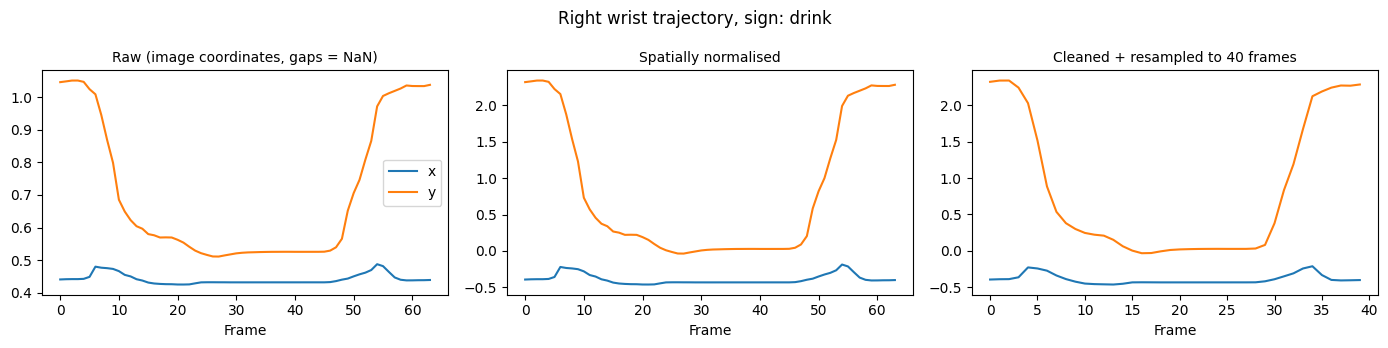

In [17]:
i = 0
vid = meta.video_id[i]
raw = np.load(f"{RAW_DIR}/{vid}.npy")
norm = spatial_normalize(raw)
final = X[i]
wrist = slice(15, 17)   # right wrist x, y (pose landmark index 5)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, data, title in zip(axs, [raw, norm, final],
                           ["Raw (image coordinates, gaps = NaN)", "Spatially normalised", f"Cleaned + resampled to {T} frames"]):
    ax.plot(data[:, 15], label="x"); ax.plot(data[:, 16], label="y")
    ax.set_title(title, fontsize=10); ax.set_xlabel("Frame")
axs[0].legend()
fig.suptitle(f"Right wrist trajectory, sign: {meta.gloss[i]}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/preprocessing_example.png", dpi=150); plt.show()

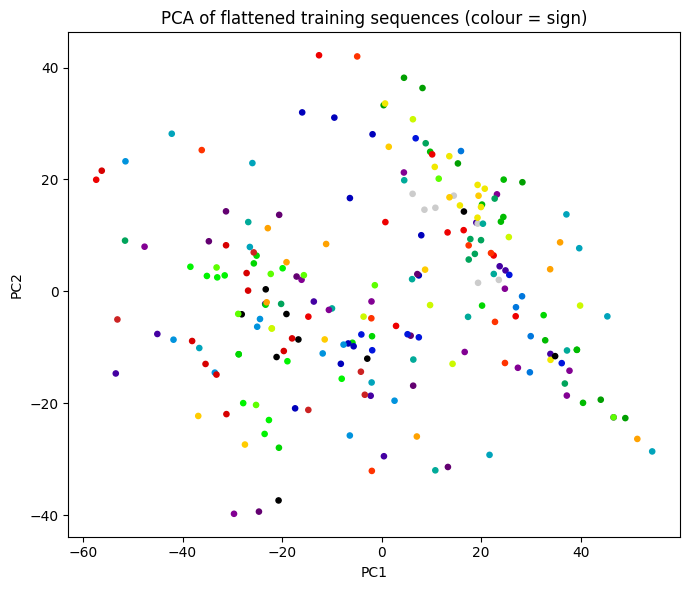

In [18]:
flat = X_train.reshape(len(X_train), -1)
pcs = PCA(n_components=2, random_state=SEED).fit_transform(flat)
plt.figure(figsize=(7, 6))
sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=y_train, cmap=plt.get_cmap("nipy_spectral", len(classes)), s=14)
plt.title("PCA of flattened training sequences (colour = sign)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/pca_feature_space.png", dpi=150); plt.show()

## 12. Data augmentation (training set only)
With only ~15 to 30 videos per sign, small random changes help the model generalise: scaling, small rotation, shift, noise and a mild speed change. Validation and test data are never augmented.

In [19]:
def augment(seq, rng):
    s = seq.reshape(len(seq), -1, 3).copy()
    s *= rng.uniform(0.9, 1.1)                                   # scale
    th = np.deg2rad(rng.uniform(-10, 10))                        # rotation in the image plane
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    s[..., :2] = s[..., :2] @ R.T
    s[..., :2] += rng.normal(0, 0.03, size=(1, 1, 2))            # shift
    s += rng.normal(0, 0.01, size=s.shape)                       # jitter
    out = s.reshape(len(seq), -1)
    gamma = rng.uniform(0.8, 1.25)                               # speed change (time warp)
    old = np.linspace(0, 1, len(out)); new = np.linspace(0, 1, len(out)) ** gamma
    out = np.stack([np.interp(new, old, out[:, j]) for j in range(out.shape[1])], axis=1)
    return out.astype(np.float32)

AUG_COPIES = 2
rng = np.random.default_rng(SEED)
aug_X = [augment(s, rng) for _ in range(AUG_COPIES) for s in X_train]
aug_y = np.tile(y_train, AUG_COPIES)

X_train_aug = np.concatenate([X_train, np.array(aug_X)], axis=0)
y_train_aug = np.concatenate([y_train, aug_y], axis=0)
print("Train (original):", X_train.shape, "| Train (with augmentation):", X_train_aug.shape)

Train (original): (217, 40, 144) | Train (with augmentation): (651, 40, 144)


## 13. Save everything for Person 2
Saves the arrays, label map, metadata and config into `/kaggle/working/processed/`. Download this folder (Output tab, or **Save Version**) and share it with your teammate.

In [20]:
np.savez_compressed(f"{OUT_DIR}/wlasl{len(classes)}_landmarks.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test,
                    X_train_aug=X_train_aug, y_train_aug=y_train_aug)

with open(f"{OUT_DIR}/label_map.json", "w") as f:
    json.dump(label_map, f, indent=2)

config = dict(num_classes=len(classes), time_steps=T, num_features=N_FEATS,
              feature_layout={"pose(6 landmarks: L/R shoulder, L/R elbow, L/R wrist)": "0:18",
                              "left_hand(21)": "18:81", "right_hand(21)": "81:144"},
              coordinates="x,y,z per landmark; relative to shoulder mid-point, divided by shoulder width",
              split_mode=SPLIT_MODE, seed=SEED)
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump(config, f, indent=2)

meta.to_csv(f"{OUT_DIR}/metadata.csv", index=False)
print(os.listdir(OUT_DIR))

['metadata.csv', 'label_map.json', 'config.json', 'figures', 'wlasl25_landmarks.npz']


## 14. Verify the hand-off
Reload the saved file exactly as Person 2 will. Shapes and labels should match.

In [21]:
d = np.load(f"{OUT_DIR}/wlasl{len(classes)}_landmarks.npz")
for k in d.files:
    print(k, d[k].shape, d[k].dtype)
with open(f"{OUT_DIR}/label_map.json") as f:
    lm = json.load(f)
inv = {v: k for k, v in lm.items()}
print("Example label:", int(d["y_train"][0]), "=", inv[int(d["y_train"][0])])
assert not np.isnan(d["X_train"]).any()

X_train (217, 40, 144) float32
y_train (217,) int64
X_val (49, 40, 144) float32
y_val (49,) int64
X_test (32, 40, 144) float32
y_test (32,) int64
X_train_aug (651, 40, 144) float32
y_train_aug (651,) int64
Example label: 12 = drink


## 15. Demo preprocessing check
`preprocess_video()` turns any video file into the exact model input format. For the live demo, record a short clip of a sign, pass its path here, and give the result to the trained model. Test it on one dataset video:

In [22]:
sample_path = video_paths[meta.video_id[0]]
demo_x = preprocess_video(sample_path)
print("Model input shape:", demo_x.shape)   # expected: (1, T, 144)

W0000 00:00:1791041858.320735    5187 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041858.336652    5187 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041858.337853    5186 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041858.337935    5187 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041858.338161    5184 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791041858.343978    5184 inference_feedback_manager.cc:114] Feedback manager 

Model input shape: (1, 40, 144)


In [23]:
import shutil
shutil.make_archive("/kaggle/working/processed_bundle", "zip", OUT_DIR)

'/kaggle/working/processed_bundle.zip'